In [1]:
# Kaggle setup: clone the repo (src/ code), install libraries, find the competition data.
# Needs: Internet ON, competition data added as input.
import os, glob, subprocess

REPO = "polluvl/hw2-video-detection"

if os.path.isdir("/kaggle/working"):
    # 1. clone the repo once per session
    if not os.path.isdir("/kaggle/working/repo"):
        r = subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO}.git", "/kaggle/working/repo"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("git clone failed (is Internet on?):\n" + r.stderr)
    # 2. install the pinned libraries
    subprocess.run(["pip", "install", "-q", "-r", "/kaggle/working/repo/requirements.txt"], check=True)
    os.chdir("/kaggle/working/repo/notebooks")

    # 3. find where Kaggle mounted the competition data
    hits = glob.glob("/kaggle/input/**/test_images.csv", recursive=True)
    if not hits:
        raise RuntimeError("Competition data not found: add it in the right panel under Input")
    os.environ["DATA_ROOT"] = os.path.dirname(hits[0])
    print("data root:", os.environ["DATA_ROOT"])

data root: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


# 01 · Data understanding and preprocessing
Goals: class balance, object sizes, objects per frame (and how they vary between clips),
ignored regions, frame redundancy (to choose a subsampling step), check the label
conversion visually, and fit anchor statistics on the **training split only**.

In [2]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
sys.path.insert(0, str(Path("src").resolve()))
from common import (CLASS_NAMES, find_data_root, list_frames, list_test_frames,
                    read_ignore, read_labels, seed_everything, work_dir)

seed_everything(42)
DATA = find_data_root()
OUT = work_dir()
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
print("data:", DATA)

data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Frames, clips and image sizes

In [3]:
train_frames = list_frames(DATA / "train")
val_frames = list_frames(DATA / "val")
test_frames = list_test_frames(DATA)
assert not set(train_frames["clip"]) & set(val_frames["clip"]), "train/val share a clip!"

for name, df in [("train", train_frames), ("val", val_frames), ("test", test_frames)]:
    sizes = df.groupby(["width", "height"]).clip.nunique().to_dict()
    print(f"{name}: {df['clip'].nunique()} clips, {len(df)} frames, clips per resolution {sizes}")

train: 56 clips, 24201 frames, clips per resolution {(1344, 756): 11, (1360, 765): 1, (1904, 1071): 30, (1920, 1080): 1, (2688, 1512): 11, (2720, 1530): 2}
val: 7 clips, 2846 frames, clips per resolution {(1344, 756): 2, (1904, 1071): 2, (2688, 1512): 1, (2720, 1530): 1, (3840, 2160): 1}
test: 48 clips, 3811 frames, clips per resolution {(680, 382): 3, (960, 540): 5, (1344, 756): 7, (1360, 764): 18, (1904, 1072): 4, (1920, 1080): 11}


## 2. Collect every box into one table

In [4]:
def collect_boxes(frames, split):
    rows, ign_rows = [], []
    for r in frames.itertuples():
        boxes, classes = read_labels(r.label_path, r.width, r.height)
        for (x1, y1, x2, y2), c in zip(boxes, classes):
            rows.append((split, r.clip, r.frame, int(c), x2 - x1, y2 - y1, r.width, r.height))
        for x1, y1, x2, y2 in read_ignore(r.ignore_path, r.width, r.height):
            ign_rows.append((split, r.clip, r.frame, (x2 - x1) * (y2 - y1) / (r.width * r.height)))
    boxes = pd.DataFrame(rows, columns=["split", "clip", "frame", "cls", "w", "h", "img_w", "img_h"])
    ignores = pd.DataFrame(ign_rows, columns=["split", "clip", "frame", "area_frac"])
    return boxes, ignores

train_boxes, train_ign = collect_boxes(train_frames, "train")
val_boxes, val_ign = collect_boxes(val_frames, "val")
boxes = pd.concat([train_boxes, val_boxes], ignore_index=True)
boxes["class"] = boxes.cls.map(dict(enumerate(CLASS_NAMES)))
boxes["size"] = np.sqrt(boxes.w * boxes.h)  # side of an equal-area square, in pixels
boxes["coco_bucket"] = pd.cut(boxes.w * boxes.h, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
print(len(train_boxes), "train boxes,", len(val_boxes), "val boxes")

1105516 train boxes, 114132 val boxes


### Sanity check of the conversion: our counts vs. `annotations_coco.json`

In [5]:
for split, b in [("train", train_boxes), ("val", val_boxes)]:
    coco_path = DATA / split / "annotations_coco.json"
    if coco_path.exists():
        with open(coco_path) as f:
            coco = json.load(f)
        n_obj = sum(a.get("iscrowd", 0) == 0 for a in coco["annotations"])
        n_crowd = sum(a.get("iscrowd", 0) == 1 for a in coco["annotations"])
        n_ign = len(train_ign if split == "train" else val_ign)
        print(f"{split}: objects {len(b)} (txt) vs {n_obj} (coco) | ignored {n_ign} (txt) vs {n_crowd} (coco)")

train: objects 1105516 (txt) vs 1105516 (coco) | ignored 63843 (txt) vs 510744 (coco)
val: objects 114132 (txt) vs 114132 (coco) | ignored 3995 (txt) vs 31960 (coco)


## 3. Class distribution (overall and per clip)

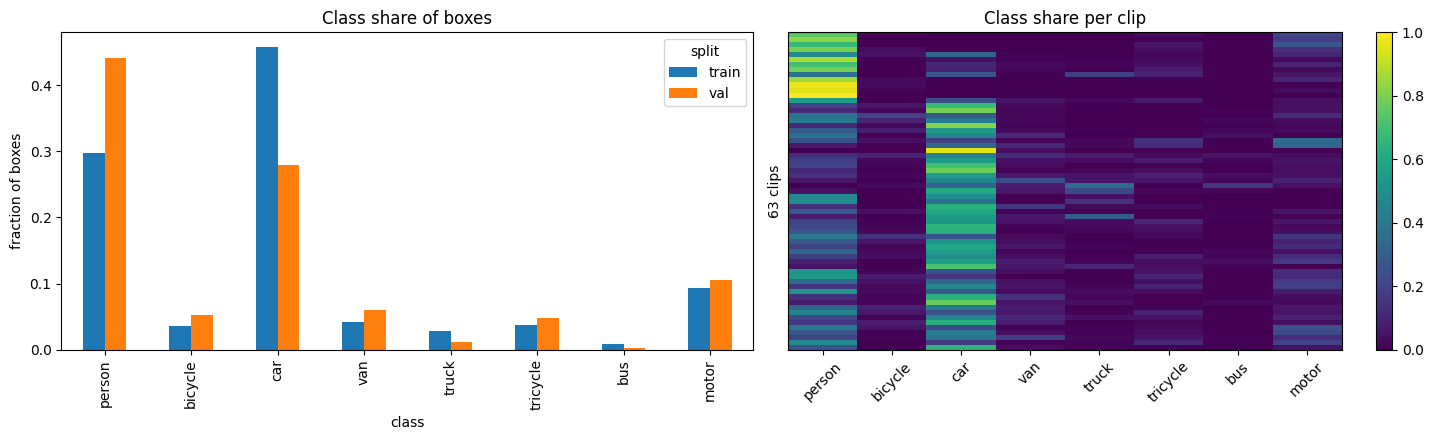

split      train    val  train_pct
class                             
person    328701  50312       29.7
bicycle    40255   6022        3.6
car       505301  31821       45.7
van        46940   6842        4.2
truck      30498   1359        2.8
tricycle   41349   5487        3.7
bus         9653    264        0.9
motor     102819  12025        9.3
clips in which each class appears at all:
 class
person      62
bicycle     46
car         55
van         52
truck       44
tricycle    44
bus         25
motor       56
dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
counts = boxes.groupby(["class", "split"]).size().unstack().reindex(CLASS_NAMES)
(counts / counts.sum()).plot.bar(ax=axes[0], title="Class share of boxes")
axes[0].set_ylabel("fraction of boxes")
per_clip = boxes.groupby(["clip", "class"]).size().unstack(fill_value=0)[CLASS_NAMES]
per_clip = per_clip.div(per_clip.sum(axis=1), axis=0)
im = axes[1].imshow(per_clip.values, aspect="auto", cmap="viridis")
axes[1].set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45)
axes[1].set_yticks([])
axes[1].set_ylabel(f"{len(per_clip)} clips")
axes[1].set_title("Class share per clip")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.savefig(FIG / "class_distribution.png", dpi=120)
plt.show()
print(counts.assign(train_pct=lambda d: (100 * d.train / d.train.sum()).round(1)))
print("clips in which each class appears at all:\n", (per_clip > 0).sum())

## 4. Object sizes

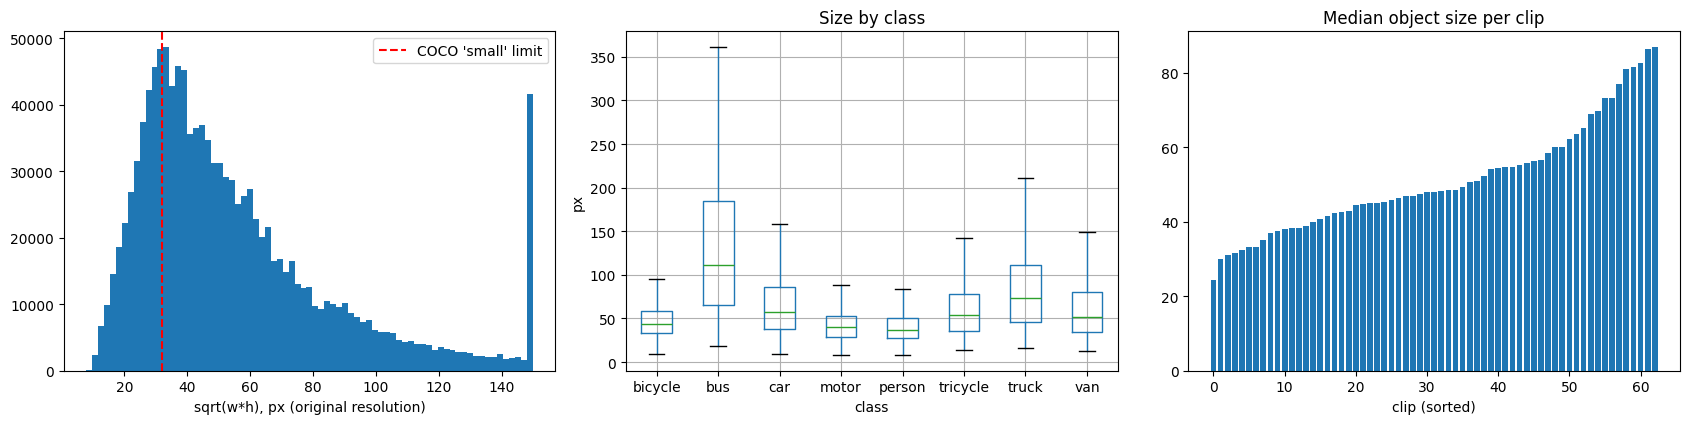

COCO size buckets:
 coco_bucket
medium    0.641
small     0.244
large     0.116
Name: proportion, dtype: float64
size percentiles (px): {0.05: 19.9, 0.25: 32.3, 0.5: 46.4, 0.75: 68.8, 0.95: 130.3}
aspect ratio h/w percentiles: {0.05: 0.41, 0.5: 1.07, 0.95: 2.56}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(boxes["size"].clip(upper=150), bins=75)
axes[0].axvline(32, color="r", ls="--", label="COCO 'small' limit")
axes[0].set_xlabel("sqrt(w*h), px (original resolution)")
axes[0].legend()
boxes.boxplot(column="size", by="class", ax=axes[1], showfliers=False)
axes[1].set_title("Size by class")
axes[1].set_ylabel("px")
clip_size = boxes.groupby("clip")["size"].median().sort_values()
axes[2].bar(range(len(clip_size)), clip_size.values)
axes[2].set_title("Median object size per clip")
axes[2].set_xlabel("clip (sorted)")
plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG / "object_sizes.png", dpi=120)
plt.show()

print("COCO size buckets:\n", boxes.coco_bucket.value_counts(normalize=True).round(3))
print("size percentiles (px):", boxes["size"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_dict())
print("aspect ratio h/w percentiles:", (boxes.h / boxes.w).quantile([0.05, 0.5, 0.95]).round(2).to_dict())

## 5. Scene density: objects per frame

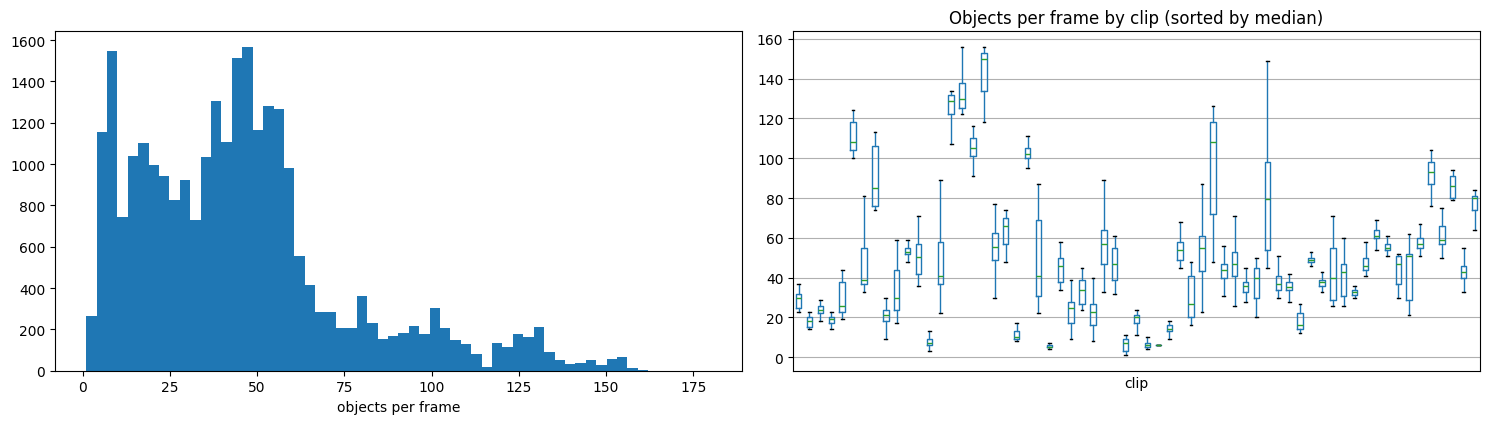

objects/frame percentiles: {0.5: 42.0, 0.9: 90.0, 0.99: 140.0, 1.0: 180.0}
frames with > 100 objects: 0.075 | > 300: 0.0


In [8]:
per_frame = boxes.groupby(["split", "clip", "frame"]).size().rename("n").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(per_frame.n, bins=60)
axes[0].set_xlabel("objects per frame")
order = per_frame.groupby("clip").n.median().sort_values().index
per_frame.boxplot(column="n", by="clip", ax=axes[1], positions=range(len(order)), showfliers=False)
axes[1].set_xticks([])
axes[1].set_title("Objects per frame by clip (sorted by median)")
plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG / "objects_per_frame.png", dpi=120)
plt.show()
print("objects/frame percentiles:", per_frame.n.quantile([0.5, 0.9, 0.99, 1.0]).to_dict())
print("frames with > 100 objects:", (per_frame.n > 100).mean().round(3), "| > 300:", (per_frame.n > 300).mean().round(4))

## 6. Ignored regions

In [9]:
all_ign = pd.concat([train_ign, val_ign])
frames_with_ign = all_ign.groupby(["clip", "frame"]).size()
n_frames = len(train_frames) + len(val_frames)
print(f"frames with ignored regions: {len(frames_with_ign) / n_frames:.1%}")
print("ignored area per frame (when present):",
      all_ign.groupby(["clip", "frame"]).area_frac.sum().quantile([0.5, 0.9, 1.0]).round(3).to_dict())

frames with ignored regions: 72.2%
ignored area per frame (when present): {0.5: 0.016, 0.9: 0.082, 1.0: 0.385}


## 7. How redundant are neighbouring frames? (to pick the subsampling step)
Mean absolute grey-level difference between frame t and t+k on downscaled frames.

In [10]:
def frame_diff(frames, clip, k, n=20):
    paths = frames[frames["clip"] == clip].sort_values("frame").img_path.tolist()
    diffs = []
    for i in range(0, max(len(paths) - k, 0), max(1, (len(paths) - k) // n)):
        a = cv2.resize(cv2.imread(paths[i], 0), (320, 180)).astype(np.float32)
        b = cv2.resize(cv2.imread(paths[i + k], 0), (320, 180)).astype(np.float32)
        diffs.append(np.abs(a - b).mean())
    return np.mean(diffs) if diffs else np.nan

steps = [1, 2, 5, 10, 20]
clips_sample = train_frames["clip"].drop_duplicates().sample(min(8, train_frames["clip"].nunique()), random_state=0)
redundancy = pd.DataFrame({k: [frame_diff(train_frames, c, k) for c in clips_sample] for k in steps},
                          index=clips_sample)
print(redundancy.round(1))
print("mean over clips:", redundancy.mean().round(1).to_dict())

                      1     2          5          10         20
clip                                                           
uav0000316_01288_v   5.6   8.5  13.700000  18.900000  23.200001
uav0000279_00001_v   9.9  13.7  19.299999  24.200001  29.200001
uav0000307_00000_v   5.4   7.6  11.700000  14.800000  17.299999
uav0000263_03289_v   6.0   8.4  14.100000  15.200000  20.700001
uav0000099_02109_v  10.4  13.5  17.200001  20.100000  22.600000
uav0000013_01392_v   6.3   8.3  10.900000  13.000000  15.200000
uav0000278_00001_v   8.1  10.8  15.600000  19.500000  23.100000
uav0000309_00000_v  14.7  19.4  25.700001  30.400000  34.799999
mean over clips: {1: 8.300000190734863, 2: 11.300000190734863, 5: 16.0, 10: 19.5, 20: 23.299999237060547}


## 8. Visual check: ground truth (green) and ignored regions (red, hatched) on sample frames

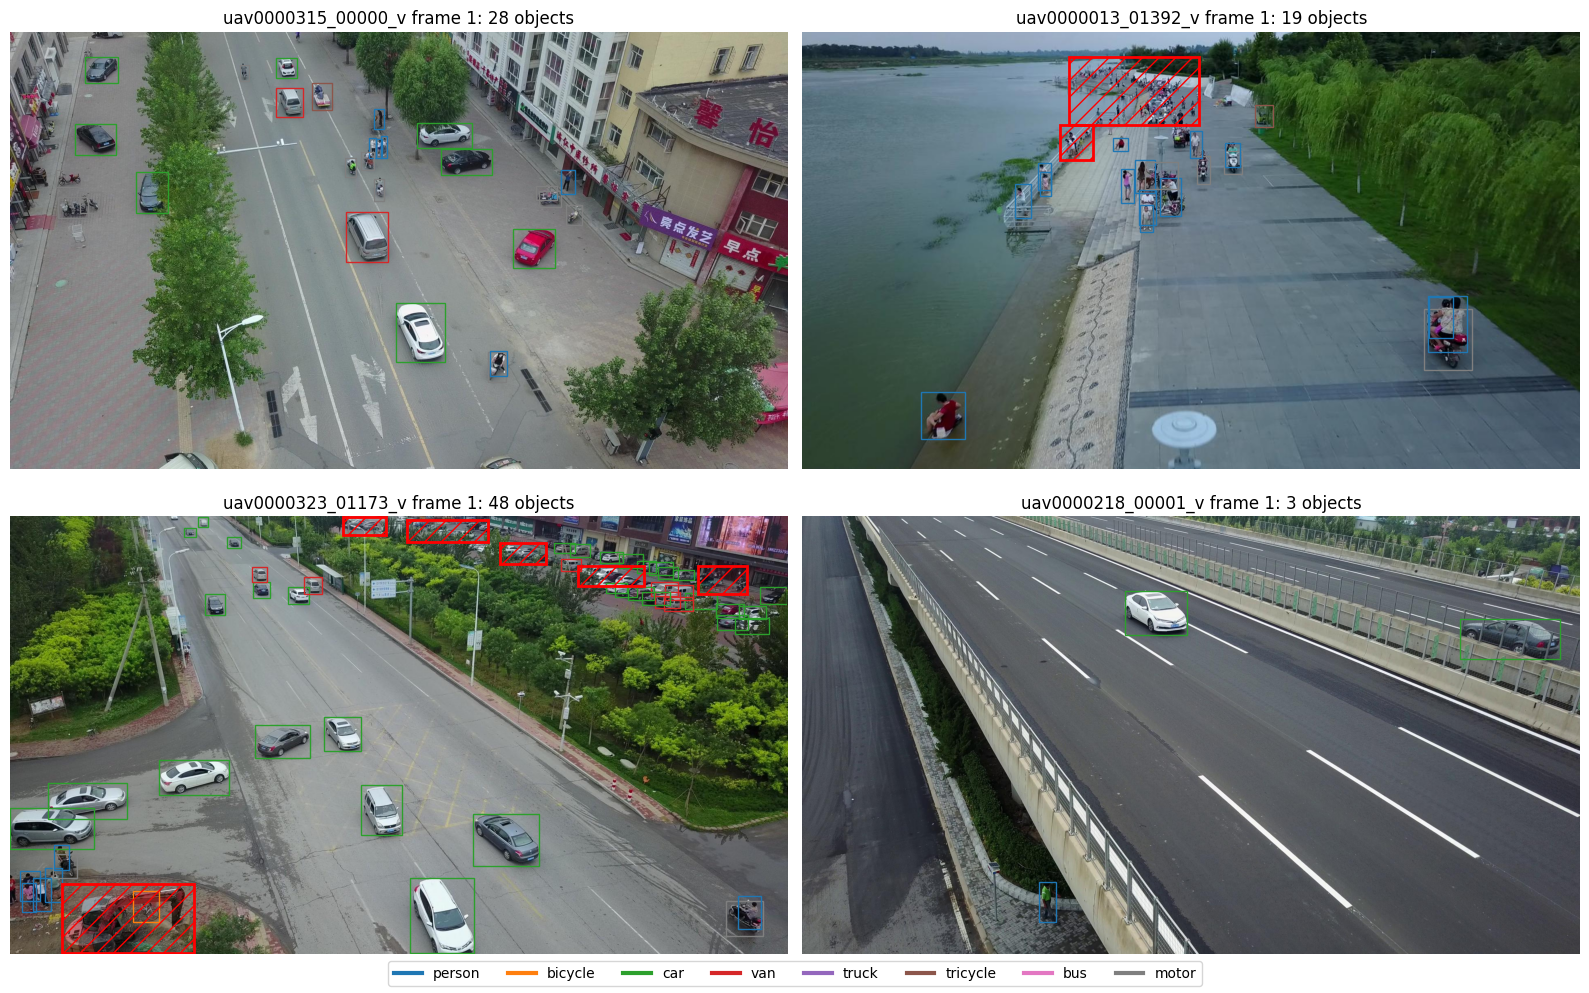

In [11]:
colours = plt.cm.tab10(np.arange(8))
sample = train_frames.groupby("clip").head(1).sample(min(4, train_frames["clip"].nunique()), random_state=1)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, r in zip(axes.ravel(), sample.itertuples()):
    ax.imshow(cv2.cvtColor(cv2.imread(r.img_path), cv2.COLOR_BGR2RGB))
    b, c = read_labels(r.label_path, r.width, r.height)
    for (x1, y1, x2, y2), k in zip(b, c):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=colours[k], lw=1))
    for x1, y1, x2, y2 in read_ignore(r.ignore_path, r.width, r.height):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2, hatch="//"))
    ax.set_title(f"{r.clip} frame {r.frame}: {len(b)} objects")
    ax.axis("off")
handles = [plt.Line2D([], [], color=colours[i], lw=3, label=n) for i, n in enumerate(CLASS_NAMES)]
fig.legend(handles=handles, loc="lower center", ncol=8)
plt.tight_layout()
plt.savefig(FIG / "gt_check.png", dpi=110)
plt.show()

## 9. Anchor statistics — fitted on the TRAIN split only
torchvision resizes so the short side is 800 px (long side max 1333). Anchors live in that
resized space, so box sizes are rescaled the same way before clustering
(k-means on box shapes, as in YOLOv2).

In [12]:
from sklearn.cluster import KMeans

tb = train_boxes.copy()
scale = np.minimum(800 / np.minimum(tb.img_w, tb.img_h), 1333 / np.maximum(tb.img_w, tb.img_h))
tb["w_r"], tb["h_r"] = tb.w * scale, tb.h * scale
tb["size_r"] = np.sqrt(tb.w_r * tb.h_r)
print("size after resize, percentiles:", tb.size_r.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1).to_dict())

# 3 aspect ratios (h/w) from k-means on log(h/w) -> symmetric treatment of tall/wide boxes
log_ratio = np.log((tb.h_r / tb.w_r).values).reshape(-1, 1)
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(log_ratio)
ratios = sorted(float(np.exp(c[0])) for c in km.cluster_centers_)

# RetinaNet levels P3..P7 (strides 8..128). Smallest anchor ~ 5th percentile of object size,
# doubling per level, 3 scales per octave as in the RetinaNet paper.
# (not smaller than 8 px = stride of P3, otherwise neighbouring anchors would not overlap)
base = float(max(np.round(tb.size_r.quantile(0.05)), 8))
retina_sizes = [[round(base * 2**lvl * 2**(i / 3), 1) for i in range(3)] for lvl in range(5)]

# Faster R-CNN levels P2..P6 (one size per level)
frcnn_sizes = [int(round(base * 2**lvl)) for lvl in range(5)]

anchors = {"aspect_ratios": [round(r, 3) for r in ratios], "retina_anchor_sizes": retina_sizes,
           "frcnn_anchor_sizes": frcnn_sizes, "fitted_on": "train split only"}
print(json.dumps(anchors, indent=1))
with open(OUT / "anchors.json", "w") as f:
    json.dump(anchors, f, indent=1)

# how many objects are smaller than the smallest DEFAULT anchor (32 px)?
print(f"objects smaller than 32 px after resize: {(tb.size_r < 32).mean():.1%}")
print(f"objects smaller than 16 px after resize: {(tb.size_r < 16).mean():.1%}")

size after resize, percentiles: {0.05: 14.1, 0.25: 22.5, 0.5: 31.7, 0.75: 45.7, 0.95: 87.0}
{
 "aspect_ratios": [
  0.505,
  1.022,
  2.02
 ],
 "retina_anchor_sizes": [
  [
   14.0,
   17.6,
   22.2
  ],
  [
   28.0,
   35.3,
   44.4
  ],
  [
   56.0,
   70.6,
   88.9
  ],
  [
   112.0,
   141.1,
   177.8
  ],
  [
   224.0,
   282.2,
   355.6
  ]
 ],
 "frcnn_anchor_sizes": [
  14,
  28,
  56,
  112,
  224
 ],
 "fitted_on": "train split only"
}
objects smaller than 32 px after resize: 50.9%
objects smaller than 16 px after resize: 8.5%


## 10. Observations → decisions
TODO (write in your own words, using the numbers printed above):
- class imbalance and which classes are rare →
- share of small objects, size after resizing → input resolution, anchor sizes
- objects per frame → `detections_per_img` / max_det = 500, number of DETR queries
- frame redundancy → subsampling step (TRAIN_STEP) for protocol runs
- ignored regions → masked with mean colour during training, iscrowd=1 in evaluation